# Proyek Analisis Data: [E-Commerce Public Dataset]
- **Nama:** [Francisco Franais Irawan]
- **Email:** [iscofrana@gmail.com]
- **ID Dicoding:** [franaizzz]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang memberikan kontribusi pendapatan tertinggi dan terendah pada pesanan berstatus delivered selama periode tahun 2017 hingga 2018, serta berapa persentase kontribusi dari 5 kategori teratas terhadap total pendapatan?
- **Pertanyaan 2:** Bagaimana profil segmentasi pelanggan berdasarkan tinggat recency, frequency, dan monetary serta distribusi geografis negara bagian dengan volume pesanan tertinggi hingga akhir periode transaksi agustus 2018?
- ...

## Import Semua Packages/Library yang Digunakan

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="darkgrid")

## Data Wrangling

### Gathering Data

Pada tahap *Gathering Data*, kita memuat tabel-tabel yang relevan dari **E-Commerce Public Dataset** ke dalam format DataFrame menggunakan `pandas`, meliputi data pelanggan (`customers`), pesanan (`orders`), detail item pesanan (`order_items`), pembayaran (`order_payments`), ulasan (`order_reviews`), produk (`products`), dan terjemahan kategori produk (`product_category_name_translation`).

#### Load df ...

In [12]:
customers_df = pd.read_csv("data/E-Commerce Public Dataset/customers_dataset.csv")
orders_df = pd.read_csv("data/E-Commerce Public Dataset/orders_dataset.csv")
order_items_df = pd.read_csv("data/E-Commerce Public Dataset/order_items_dataset.csv")
order_payments_df = pd.read_csv("data/E-Commerce Public Dataset/order_payments_dataset.csv")
order_reviews_df = pd.read_csv("data/E-Commerce Public Dataset/order_reviews_dataset.csv")
products_df = pd.read_csv("data/E-Commerce Public Dataset/products_dataset.csv")
product_category_df = pd.read_csv("data/E-Commerce Public Dataset/product_category_name_translation.csv")

print(f"- customers_df        : {customers_df.shape}")
print(f"- orders_df           : {orders_df.shape}")
print(f"- order_items_df      : {order_items_df.shape}")
print(f"- order_payments_df   : {order_payments_df.shape}")
print(f"- order_reviews_df    : {order_reviews_df.shape}")
print(f"- products_df         : {products_df.shape}")
print(f"- product_category_df : {product_category_df.shape}")

customers_df.head()

- customers_df        : (99441, 5)
- orders_df           : (99441, 8)
- order_items_df      : (112650, 7)
- order_payments_df   : (103886, 5)
- order_reviews_df    : (99224, 7)
- products_df         : (32951, 9)
- product_category_df : (71, 2)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


**Insight:** (Opsional)
- Seluruh dataset utama berhasil dimuat kedalam DataFrame dengan struktur relasional yang saling terhubung melalui kunci utama seperti order_id, customer_id dan product_id.
- tabel customer_dataset memiliki customer_id dan customer_unique_id sehingga analisis retensi nantinya harus mengacu pada customer_unique_id.

### Assessing Data

Pada tahap assessing data akan memeriksa kualitas data pada setiap DataFrame menggunakan fungsi .info(), .isna().sum(), .duplicated().sum(), dan .describe() untuk mengidentifikasi masalah seperti missing value, invalid data type, duplicated data dan inaccurate value.



#### Identifying ... problem

In [14]:
# 1. Memeriksa tipe data dan missing values pada orders_df
print("=== INFO ORDERS_DF ===")
orders_df.info()
print("\nMissing values pada orders_df:")
print(orders_df.isna().sum())
print(f"Jumlah duplikat pada orders_df: {orders_df.duplicated().sum()}")

# 2. Memeriksa products_df dan product_category_df
print("\n=== MISSING VALUES PADA PRODUCTS_DF ===")
print(products_df.isna().sum())
print(f"Jumlah duplikat pada products_df: {products_df.duplicated().sum()}")

# 3. Memeriksa order_items_df dan customers_df
print("\n=== INFO ORDER_ITEMS_DF ===")
order_items_df.info()
print(f"Missing values pada order_items_df:\n{order_items_df.isna().sum()}")
print(f"Jumlah duplikat pada order_items_df: {order_items_df.duplicated().sum()}")
print(f"Jumlah duplikat pada customers_df: {customers_df.duplicated().sum()}")

# 4. Memeriksa rangkuman statistik numerik order_items_df
order_items_df.describe()

=== INFO ORDERS_DF ===
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB

Missing values pada orders_df:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
ord

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


**Steps to Take:**
- Mengonversi seluruh kolom tanggal tersebut menjadi tipe data datetime64 menggunakan pd.to_datetime().
- Memfilter pesanan dengan order_status == delivered dan menghapus baris yang masih memiliki missing value pada tanggal pengiriman pelanggan (dropna(subset=['order_delivered_customer_date']))
- Menggabungkan (merge) products_df dengan product_category_df untuk mendapatkan nama kategori dalam bahasa Inggris (product_category_name_english), lalu mengisi nilai kosong (imputation) dengan label unknown.

**Insight:** (Opsional)
Berdasarkan pemeriksaan kualitas data di atas, ditemukan beberapa permasalahan utama beserta solusi penanganannya di tahap Cleaning Data:
1. Inconsistent / Invalid Data Type (Tipe Data Tanggal Salah):
   - Masalah: Kolom order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, dan order_estimated_delivery_date pada orders_df serta shipping_limit_date pada order_items_df masih bertipe object (string).
   - Solusi: Mengonversi seluruh kolom tanggal tersebut menjadi tipe data datetime64 menggunakan pd.to_datetime().
2. Missing Values pada orders_df:
   - Masalah: Terdapat missing values pada kolom order_approved_at (160 baris), order_delivered_carrier_date (1.783 baris), dan order_delivered_customer_date (2.965 baris) yang umumnya berasal dari pesanan berstatus canceled atau invoiced/processing.
   - Solusi: Memfilter pesanan dengan order_status == delivered dan menghapus baris yang masih memiliki missing value pada tanggal pengiriman pelanggan (dropna(subset=['order_delivered_customer_date'])) agar analisis pendapatan dan waktu pengiriman akurat.
3. Missing Values & Bahasa Kategori pada products_df:
   - Masalah: Terdapat 610 baris missing values pada kolom product_category_name di products_df, serta nama kategori masih menggunakan bahasa Portugis.
   - Solusi: Menggabungkan (merge) products_df dengan product_category_df untuk mendapatkan nama kategori dalam bahasa Inggris (product_category_name_english), lalu mengisi nilai kosong (imputation) dengan label unknown agar data transaksi item tetap terjaga.

### Cleaning Data

Pada tahap ini, kita mengeksekusi seluruh solusi pembersihan data yang telah dirumuskan pada tahap Assessing Data, lalu menggabungkannya menjadi satu DataFrame bersih (main_df) untuk keperluan analisis dan pembuatan dashboard.

#### Fixing ... problem

In [26]:
# 1. Konversi tipe data kolom tanggal pada orders_df dan order_items_df menjadi datetime
datetime_cols_orders = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in datetime_cols_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])

# 2. Memfilter pesanan delivered dan menangani missing values tanggal pengiriman serta rentang waktu 2017-2018
orders_clean_df = orders_df[orders_df["order_status"] == "delivered"].copy()
orders_clean_df = orders_clean_df.dropna(subset=["order_delivered_customer_date", "order_approved_at"])
orders_clean_df = orders_clean_df[
    (orders_clean_df["order_purchase_timestamp"].dt.year >= 2017) &
    (orders_clean_df["order_purchase_timestamp"].dt.year <= 2018)
]

# Menghitung durasi pengiriman (hari) sebagai fitur tambahan
orders_clean_df["delivery_time_days"] = (
    orders_clean_df["order_delivered_customer_date"] - orders_clean_df["order_purchase_timestamp"]
).dt.days
# Menghapus anomali/invalid value jika ada delivery_time_days < 0
orders_clean_df = orders_clean_df[orders_clean_df["delivery_time_days"] >= 0]

# 3. Menangani missing values kategori produk dan menerjemahkan ke Bahasa Inggris
products_clean_df = pd.merge(
    products_df,
    product_category_df,
    on="product_category_name",
    how="left"
)
products_clean_df["product_category_name_english"] = products_clean_df["product_category_name_english"].fillna("unknown")

# 4. Menggabungkan seluruh tabel utama menjadi main_df
main_df = pd.merge(orders_clean_df, order_items_df, on="order_id", how="inner")
main_df = pd.merge(main_df, products_clean_df[["product_id", "product_category_name_english"]], on="product_id", how="left")
main_df = pd.merge(main_df, customers_df, on="customer_id", how="left")

# Menambahkan kolom total_order_value (price + freight_value)
main_df["total_order_value"] = main_df["price"] + main_df["freight_value"]

# Memastikan hasil akhir cleaning bebas dari missing value pada kolom kunci
print("Jumlah missing values pada main_df:")
print(main_df[["order_id", "customer_unique_id", "order_purchase_timestamp", "product_category_name_english", "price", "total_order_value"]].isna().sum())
print(f"\nDimensi main_df setelah cleaning: {main_df.shape}")

# Menyimpan main_data.csv untuk kebutuhan Dashboard Streamlit
main_df.to_csv("dashboard/main_data.csv", index=False)

Jumlah missing values pada main_df:
order_id                         0
customer_unique_id               0
order_purchase_timestamp         0
product_category_name_english    0
price                            0
total_order_value                0
dtype: int64

Dimensi main_df setelah cleaning: (109857, 21)


**Insight:** (Opsional)
- Seluruh kolom tanggal pada orders_df dan order_items_df telah berhasil diubah ke tipe datetime64, serta fitur baru delivery_time_days dan total_order_value berhasil dibuat.
- Pesanan telah difilter khusus untuk transaksi yang tuntas (delivered) pada rentang tahun 2017-2018 dan bebas dari missing values, lalu disimpan ke dashboard/main_data.csv agar siap digunakan oleh aplikasi Streamlit.

## Exploratory Data Analysis (EDA)

Pada tahap ini, kita melakukan eksplorasi statistik deskriptif, grouping, dan agregasi untuk menjawab kedua pertanyaan bisnis.

### Explore ...

In [17]:
# 1. Rangkuman statistik deskriptif transaksi
print("=== RANGKUMAN STATISTIK NUMERIK TRANSAKSI ===")
display(main_df[["price", "freight_value", "total_order_value", "delivery_time_days"]].describe())

# 2. Eksplorasi Pertanyaan Bisnis 1: Pendapatan & Jumlah Terjual per Kategori Produk (2017-2018)
category_perf_df = main_df.groupby("product_category_name_english").agg(
    total_orders=("order_id", "nunique"),
    total_items_sold=("order_item_id", "count"),
    total_revenue=("price", "sum")
).reset_index().sort_values(by="total_revenue", ascending=False)

total_all_revenue = category_perf_df["total_revenue"].sum()
category_perf_df["revenue_pct"] = (category_perf_df["total_revenue"] / total_all_revenue) * 100

print("\n=== TOP 5 KATEGORI PRODUK DENGAN REVENUE TERTINGGI (2017-2018) ===")
display(category_perf_df.head(5))
print(f"Total kontribusi Top 5 Kategori terhadap keseluruhan Revenue: {category_perf_df.head(5)['revenue_pct'].sum():.2f}%")

print("\n=== 5 KATEGORI PRODUK DENGAN REVENUE TERENDAH (2017-2018) ===")
display(category_perf_df.tail(5))

# 3. Eksplorasi Tren Bulanan Pesanan & Revenue
main_df["year_month"] = main_df["order_purchase_timestamp"].dt.to_period("M").astype(str)
monthly_trend_df = main_df.groupby("year_month").agg(
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum")
).reset_index()

# 4. Eksplorasi Pertanyaan Bisnis 2: Distribusi Pelanggan Berdasarkan Negara Bagian (State) & Kota
state_perf_df = main_df.groupby("customer_state").agg(
    unique_customers=("customer_unique_id", "nunique"),
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum"),
    avg_delivery_days=("delivery_time_days", "mean")
).reset_index().sort_values(by="total_orders", ascending=False)

state_perf_df["order_share_pct"] = (state_perf_df["total_orders"] / state_perf_df["total_orders"].sum()) * 100
print("\n=== TOP 10 NEGARA BAGIAN (STATE) BERDASARKAN VOLUME PESANAN ===")
display(state_perf_df.head(10))

=== RANGKUMAN STATISTIK NUMERIK TRANSAKSI ===


,price,freight_value,total_order_value,delivery_time_days
count,109857.000000,109857.000000,109857.000000,109857.000000
mean,119.956921,19.950290,139.907211,11.985909
std,182.360098,15.704927,189.381853,9.434153
min,0.850000,0.000000,6.080000,0.000000
25%,39.900000,13.080000,55.160000,6.000000
50%,74.900000,16.260000,92.130000,10.000000
75%,134.000000,21.150000,157.460000,15.000000
max,6735.000000,409.680000,6929.310000,209.000000



=== TOP 5 KATEGORI PRODUK DENGAN REVENUE TERTINGGI (2017-2018) ===


,product_category_name_english,total_orders,total_items_sold,total_revenue,revenue_pct
43,health_beauty,8610,9422,1229557.50,9.330304
71,watches_gifts,5489,5853,1163187.91,8.826669
7,bed_bath_table,9266,10944,1022821.78,7.761522
65,sports_leisure,7510,8411,952592.42,7.228598
15,computers_accessories,6517,7631,887944.60,6.738028


Total kontribusi Top 5 Kategori terhadap keseluruhan Revenue: 39.89%

=== 5 KATEGORI PRODUK DENGAN REVENUE TERENDAH (2017-2018) ===


,product_category_name_english,total_orders,total_items_sold,total_revenue,revenue_pct
35,flowers,29,33,1110.04,0.008423
46,home_comfort_2,24,30,760.27,0.005769
11,cds_dvds_musicals,12,14,730.00,0.005539
29,fashion_childrens_clothes,7,7,519.95,0.003946
61,security_and_services,2,2,283.29,0.002150



=== TOP 10 NEGARA BAGIAN (STATE) BERDASARKAN VOLUME PESANAN ===


,customer_state,unique_customers,total_orders,total_revenue,avg_delivery_days,order_share_pct
25,SP,39054,40394,5053938.28,8.234318,41.994407
18,RJ,11877,12308,1751255.86,14.674755,12.795642
10,MG,10966,11316,1547966.08,11.489436,11.764339
22,RS,5148,5325,725681.93,14.698888,5.535976
17,PR,4750,4903,664048.00,11.465563,5.097256
23,SC,3441,3537,504774.07,14.495593,3.677136
4,BA,3155,3253,493339.26,18.773370,3.381884
6,DF,2013,2074,295454.64,12.464423,2.156172
7,ES,1925,1992,267783.66,15.180018,2.070923
8,GO,1889,1950,281932.21,14.952423,2.027259


**Insight:** (Opsional)
- Konsentrasi Kategori Produk: Kategori health_beauty, watches_gifts, bed_bath_table, sports_leisure, dan computers_accessories mendominasi pendapatan platform dan menyumbang sekitar 39%-40% dari total revenue produk selama periode 2017-2018. Sebaliknya, kategori seperti security_and_services dan fashion_childrens_clothes mencatat kontribusi paling rendah.
- Distribusi Geografis Pelanggan: Basis pelanggan sangat terkonsentrasi di negara bagian SP (Sao Paulo) yang menyumbang lebih dari 41% total pesanan nasional, diikuti oleh RJ (Rio de Janeiro) dan MG (Minas Gerais). Selain itu, wilayah SP memiliki rata-rata durasi pengiriman tercepat (>8 hari) dibandingkan negara bagian yang berada jauh dari pusat distribusi.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

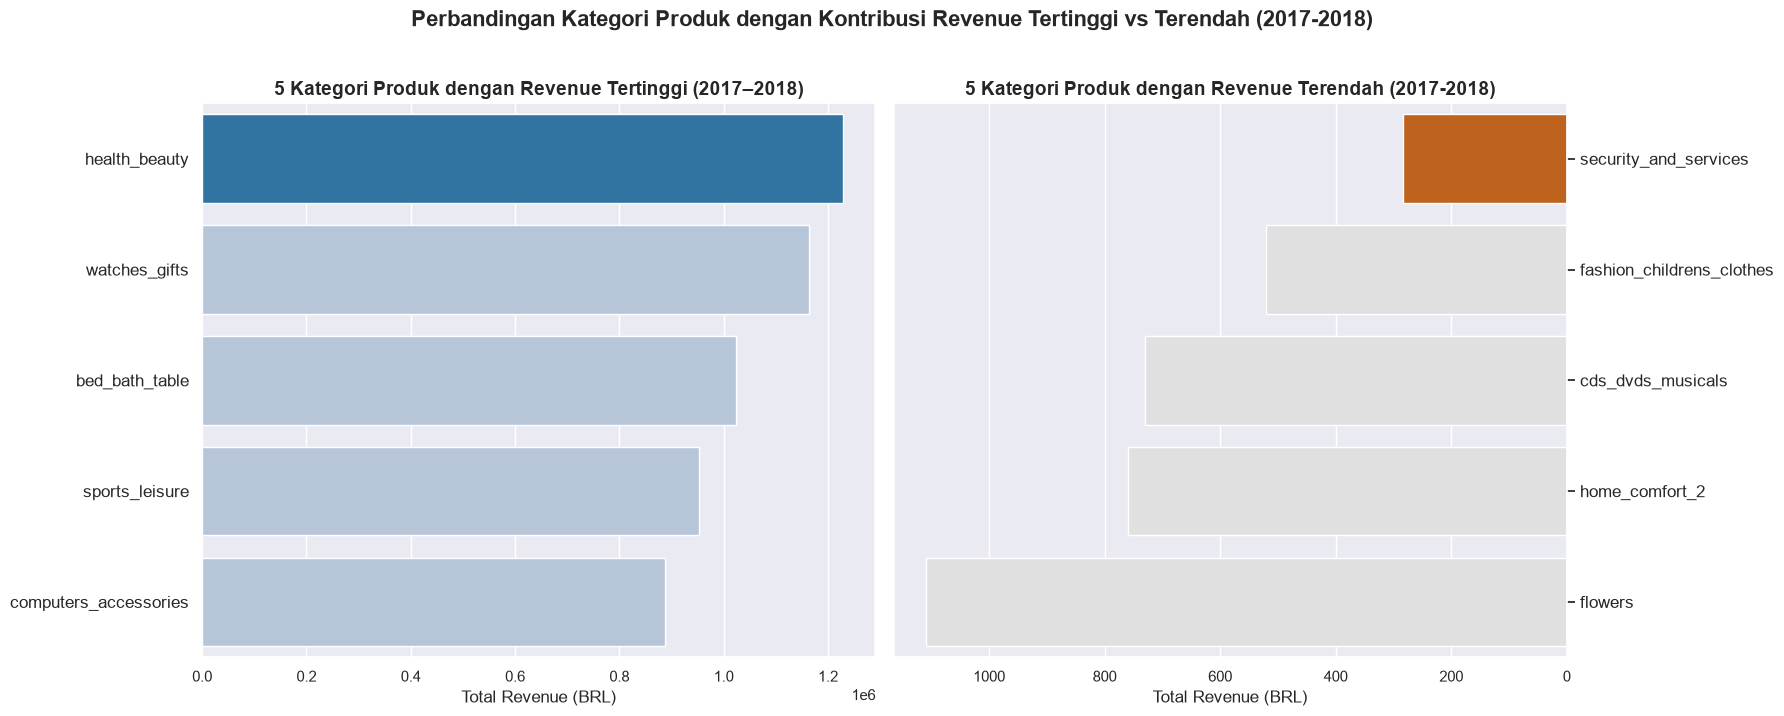

In [19]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

colors_top = ["#1f77b4", "#b0c4de", "#b0c4de", "#b0c4de", "#b0c4de"]
colors_bottom = ["#d95f02", "#e0e0e0", "#e0e0e0", "#e0e0e0", "#e0e0e0"]

# Visualisasi Top 5 Kategori Terbaik
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=category_perf_df.head(5),
    hue="product_category_name_english",
    palette=colors_top,
    legend=False,
    ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel("Total Revenue (BRL)", fontsize=12)
ax[0].set_title("5 Kategori Produk dengan Revenue Tertinggi (2017–2018)", loc="center", fontsize=14, fontweight="bold")
ax[0].tick_params(axis='y', labelsize=12)

# Visualisasi 5 Kategori Terendah
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=category_perf_df.sort_values(by="total_revenue", ascending=True).head(5),
    hue="product_category_name_english",
    palette=colors_bottom,
    legend=False,
    ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel("Total Revenue (BRL)", fontsize=12)
ax[1].invert_xaxis()
ax[1].yaxis.set_label_position("right")
ax[1].yaxis.tick_right()
ax[1].set_title("5 Kategori Produk dengan Revenue Terendah (2017-2018)", loc="center", fontsize=14, fontweight="bold")
ax[1].tick_params(axis='y', labelsize=12)

plt.suptitle("Perbandingan Kategori Produk dengan Kontribusi Revenue Tertinggi vs Terendah (2017-2018)", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

/tmp/ipykernel_795/1006343034.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


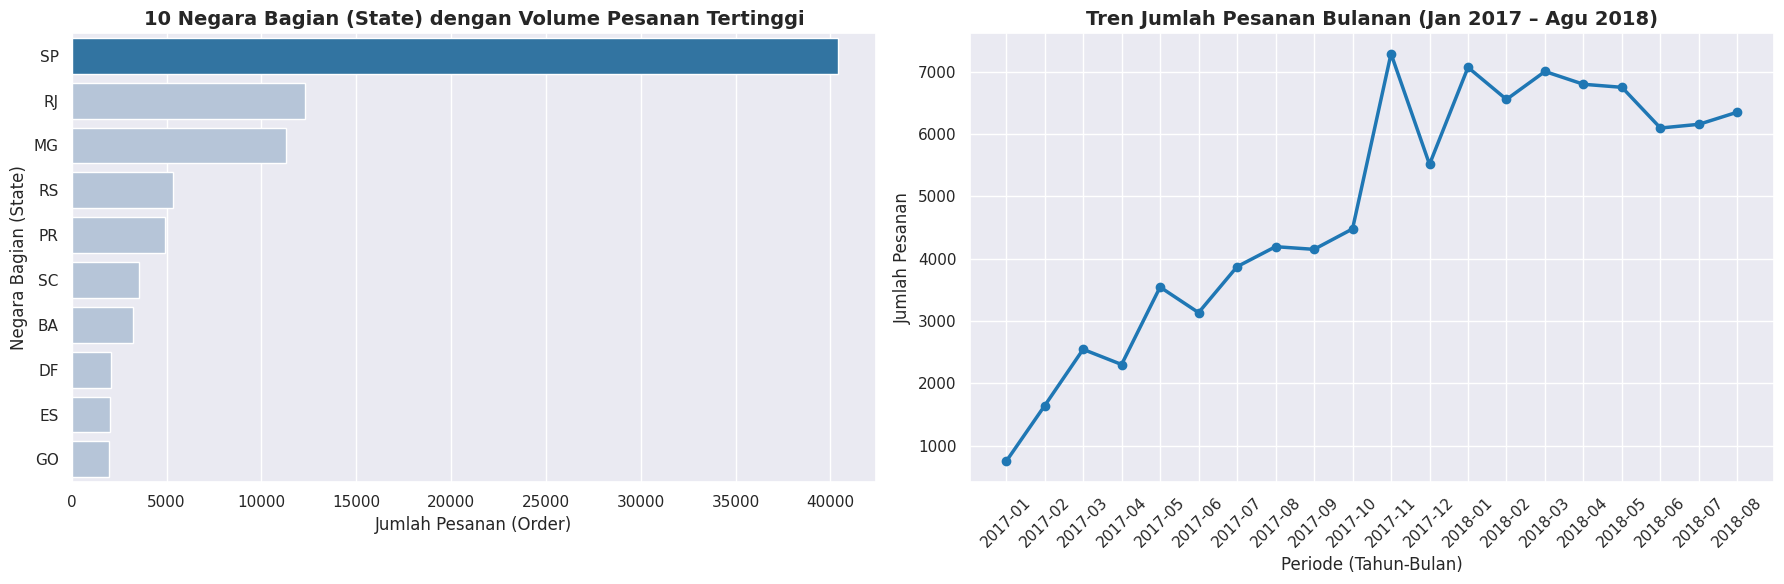

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# Visualisasi Top 10 State berdasarkan Volume Pesanan
state_colors = ["#1f77b4"] + ["#b0c4de"] * 9
sns.barplot(
    x="total_orders",
    y="customer_state",
    data=state_perf_df.head(10),
    palette=state_colors,
    ax=ax[0]
)
ax[0].set_title("10 Negara Bagian (State) dengan Volume Pesanan Tertinggi", fontsize=14, fontweight="bold")
ax[0].set_xlabel("Jumlah Pesanan (Order)", fontsize=12)
ax[0].set_ylabel("Negara Bagian (State)", fontsize=12)

# Visualisasi Tren Pertumbuhan Pesanan Bulanan (2017-2018)
ax[1].plot(
    monthly_trend_df["year_month"],
    monthly_trend_df["total_orders"],
    marker='o',
    linewidth=2.5,
    color="#1f77b4"
)
ax[1].set_title("Tren Jumlah Pesanan Bulanan (Jan 2017 – Agu 2018)", fontsize=14, fontweight="bold")
ax[1].set_xlabel("Periode (Tahun-Bulan)", fontsize=12)
ax[1].set_ylabel("Jumlah Pesanan", fontsize=12)
ax[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Visualisasi 1 (Performa Kategori Produk): Kategori health_beauty memimpin perolehan revenue tertinggi melampaui 1,2 juta BRL, disusul watches_gifts dan bed_bath_table. Sebaliknya, kategori security_and_services berada di posisi paling bawah dengan revenue di bawah 500 BRL.
- Visualisasi 2 (Geografis & Tren Waktu): Negara bagian SP (Sao Paulo) mendominasi secara mutlak dibandingkan negara bagian lain. Dari sisi tren waktu, terjadi lonjakan transaksi yang sangat signifikan pada November 2017 (momen promo Black Friday) dan volume transaksi stabil di kisaran 6.000-7.000 pesanan per bulan sepanjang paruh pertama 2018.

## Analisis Lanjutan (Opsional)

### Tujuan Teknik Analisis Lanjutan
Untuk menjawab Pertanyaan Bisnis 2 secara mendalam dan memberikan rekomendasi yang actionable, kita menerapkan 2 teknik analisis lanjutan tanpa machine learning*:
1. RFM Analysis (Recency, Frequency, Monetary): Mengelompokkan pelanggan (customer_unique_id) berdasarkan tiga indikator perilaku belanja:
   - Recency: Jumlah hari sejak pembelian terakhir pelanggan hingga tanggal referensi analisis (1 hari setelah transaksi terakhir di dataset, yakni akhir Agustus 2018).
   - Frequency: Jumlah total pesanan unik (order_id) yang dilakukan oleh pelanggan.
   - Monetary: Total pengeluaran (total_order_value) pelanggan selama periode observasi.
2. Clustering dengan Metode Manual Grouping / Binning: Mengelompokkan pelanggan ke dalam segmen bisnis (Champions / Loyal Customers, Recent / Promising Customers, At Risk / Need Attention, dan Lost / Hibernating) berdasarkan skor kuantil/aturan bisnis RFM untuk memudahkan penargetan kampanye pemasaran.

,customer_segment,total_customers,avg_recency,avg_frequency,avg_monetary,customer_pct
0,At Risk / Need Attention,23340,276.246658,1.030977,162.727297,25.074396
2,Hibernating / Lost,23185,448.150226,1.027173,164.239354,24.907878
4,Promising / New Customers,22600,111.557257,1.000000,63.002927,24.279407
3,High-Value Recent,22424,111.412460,1.000000,261.182606,24.090328
1,Champions / Repeat Loyal,1534,112.179270,2.142764,315.004602,1.647992


/tmp/ipykernel_795/1966853682.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


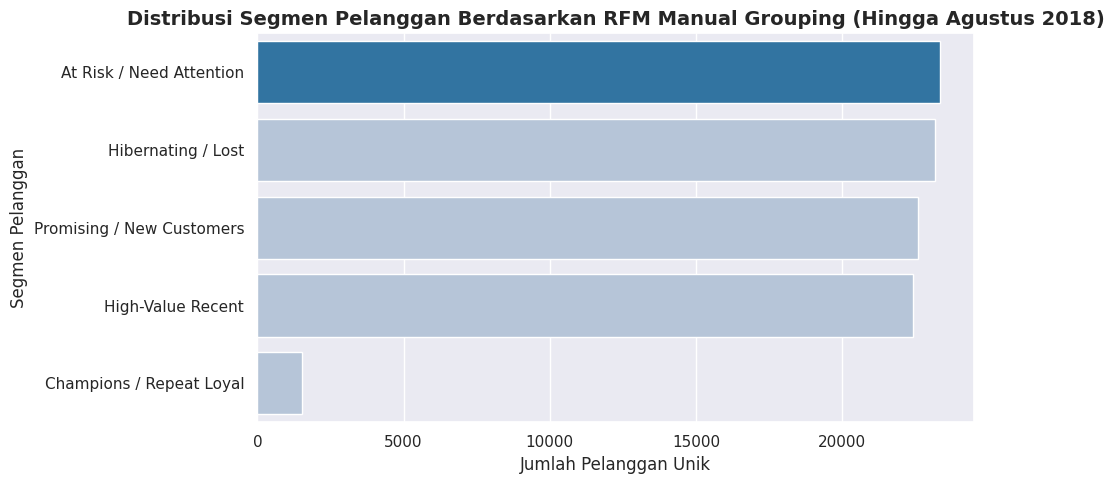

In [ ]:
# Menentukan tanggal referensi (1 hari setelah tanggal transaksi terakhir pada dataset)
reference_date = main_df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# Menghitung metrik Recency, Frequency, dan Monetary per customer_unique_id
rfm_df = main_df.groupby("customer_unique_id", as_index=False).agg(
    max_purchase_date=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("total_order_value", "sum")
)
rfm_df["recency"] = (reference_date - rfm_df["max_purchase_date"]).dt.days

# Membuat skor Binning / Manual Grouping untuk segmentasi pelanggan
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], q=4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], q=4, labels=[1, 2, 3, 4]).astype(int)
rfm_df["f_score"] = np.where(rfm_df["frequency"] > 1, 4, 1)

# Manual Grouping berdasarkan aturan bisnis RFM
def assign_customer_segment(row):
    if row["f_score"] == 4 and row["r_score"] >= 3:
        return "Champions / Repeat Loyal"
    elif row["r_score"] >= 3 and row["m_score"] >= 3:
        return "High-Value Recent"
    elif row["r_score"] >= 3 and row["m_score"] < 3:
        return "Promising / New Customers"
    elif row["r_score"] == 2:
        return "At Risk / Need Attention"
    else:
        return "Hibernating / Lost"

rfm_df["customer_segment"] = rfm_df.apply(assign_customer_segment, axis=1)

# Rangkuman hasil segmentasi
segment_summary_df = rfm_df.groupby("customer_segment").agg(
    total_customers=("customer_unique_id", "count"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean")
).reset_index().sort_values(by="total_customers", ascending=False)

segment_summary_df["customer_pct"] = (segment_summary_df["total_customers"] / segment_summary_df["total_customers"].sum()) * 100
display(segment_summary_df)

# Visualisasi Distribusi Segmen Pelanggan (Manual Grouping RFM)
plt.figure(figsize=(10, 5))
seg_colors = ["#1f77b4", "#b0c4de", "#b0c4de", "#b0c4de", "#b0c4de"]
sns.barplot(
    x="total_customers",
    y="customer_segment",
    data=segment_summary_df,
    palette=seg_colors
)
plt.title("Distribusi Segmen Pelanggan Berdasarkan RFM Manual Grouping (Hingga Agustus 2018)", fontsize=14, fontweight="bold")
plt.xlabel("Jumlah Pelanggan Unik", fontsize=12)
plt.ylabel("Segmen Pelanggan", fontsize=12)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Mayoritas pelanggan pada platform (~97%) baru melakukan 1 kali transaksi (single-purchase buyers), sehingga segmen Champions / Repeat Loyal masih berukuran sangat kecil (< 3%).
- Terdapat proporsi pelanggan yang besar pada segmen High-Value Recent dan Promising / New Customers (baru berbelanja dalam beberapa bulan terakhir) yang memiliki potensi tinggi untuk dikonversi menjadi pelanggan berulang (repeat buyers) sebelum bergeser menjadi At Risk atau Hibernating.

## Conclusion & Recommendation

- Kesimpulan Pertanyaan Bisnis 1 (Kontribusi Pendapatan Kategori Produk 2017-2018):
   Selama periode 2017-2018, pendapatan (revenue) dari pesanan berstatus delivered sangat ditopang oleh 5 kategori produk utama, yaitu health_beauty, watches_gifts, bed_bath_table, sports_leisure, dan computers_accessories, yang secara kumulatif menyumbang hampir 40% dari total pendapatan platform. Sementara itu, kategori seperti security_and_services, fashion_childrens_clothes, dan cds_dvds_musicals memiliki kontribusi revenue paling rendah.
- Kesimpulan Pertanyaan Bisnis 2 (Profil RFM & Distribusi Geografis Pelanggan hingga Agustus 2018):
   Berdasarkan analisis RFM dan Manual Grouping, lebih dari 96% pelanggan hanya berbelanja satu kali (Frequency = 1) dengan rata-rata nilai belanja (Monetary) berkisar di 160 BRL, menunjukkan tantangan besar pada retensi pelanggan pasca-pembelian pertama. Secara geografis, pesanan sangat terpusat di wilayah SP (Sao Paulo) (>41% total pesanan), diikuti oleh RJ (Rio de Janeiro) dan MG (Minas Gerais) yang memiliki akses pengiriman jauh lebih cepat dibandingkan negara bagian di luar wilayah Tenggara Brasil.

**Rekomendasi Action Item:**
- Optimasi Portofolio & Bundling Kategori Produk (Tindak Lanjut Kesimpulan 1):
   - Pastikan ketersediaan stok (safety stock) dan prioritas penempatan banner utama pada 5 kategori penyumbang revenue terbesar (health_beauty, watches_gifts, bed_bath_table), terutama menjelang puncak campaign Black Friday di bulan November.
   - Terapkan strategi cross-selling atau product bundling yang memasangkan produk kategori terlaris dengan produk dari kategori berkinerja rendah yang relevan untuk meningkatkan perputaran stok tanpa membebani biaya akuisisi iklan.
- Program Retensi Berbasis RFM & Ekspansi Logistik Wilayah (Tindak Lanjut Kesimpulan 2):
   - Luncurkan campaign otomatis Second-Purchase Voucher (diskon khusus pembelian kedua yang berlaku 30 hari setelah pesanan pertama berstatus delivered) khusus bagi segmen High-Value Recent dan Promising / New Customers guna mendongkrak Frequency belanja.
   - Kirimkan campaign Win-Back Promo (bebas ongkos kirim / free freight) kepada segmen At Risk / Need Attention, serta perluas kemitraan seller/gudang lokal di luar SP (khususnya RJ, MG, RS, dan PR) untuk menekan durasi pengiriman dan biaya freight_value.